# Smart Parking Allocation - EDA & Model Comparison

College IoE/IoT project: automated parking allocation with ML-driven peak-occupancy
alerts. This notebook is the defensible "show your work" companion to
`ml/train.py`, which is what actually ships the models the backend serves.

Dataset: UCI **"Parking Birmingham"** (id=482) - 30 car parks in Birmingham, UK,
occupancy readings roughly every ~30 minutes over Oct-Dec 2016.

Columns: `SystemCodeNumber`, `Capacity`, `Occupancy`, `LastUpdated`.

We compare three model families for predicting occupancy %:
1. Linear Regression (baseline)
2. Random Forest Regressor (what we ship)
3. A simple LSTM (sequence model, for comparison / discussion in the viva)

...and a classifier for "will occupancy cross the 85% peak threshold at the
next reading".


In [1]:
import sys
sys.path.insert(0, "..")  # so we can import ml/feature_engineering.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from feature_engineering import (
    FEATURE_COLUMNS,
    TARGET_CLASSIFICATION,
    TARGET_REGRESSION,
    engineer_features,
    load_birmingham_dataset,
    time_based_split,
    hourly_baseline_occupancy,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)


## 1. Load the raw dataset

In [2]:
raw = load_birmingham_dataset()
print(raw.shape)
raw.head()


(35717, 4)


,SystemCodeNumber,Capacity,Occupancy,LastUpdated
0,BHMBCCMKT01,577,61,2016-10-04 07:59:42
1,BHMBCCMKT01,577,64,2016-10-04 08:25:42
2,BHMBCCMKT01,577,80,2016-10-04 08:59:42
3,BHMBCCMKT01,577,107,2016-10-04 09:32:46
4,BHMBCCMKT01,577,150,2016-10-04 09:59:48


In [3]:
raw.describe(include="all")


,SystemCodeNumber,Capacity,Occupancy,LastUpdated
count,35717,35717.000000,35717.000000,35717
unique,30,NaN,NaN,NaN
top,BHMBCCMKT01,NaN,NaN,NaN
freq,1312,NaN,NaN,NaN
mean,NaN,1397.550130,642.228911,2016-11-11 18:11:47.708290
min,NaN,220.000000,-8.000000,2016-10-04 07:46:28
25%,NaN,500.000000,210.000000,2016-10-24 16:33:03
50%,NaN,849.000000,446.000000,2016-11-11 14:00:21
75%,NaN,2009.000000,798.000000,2016-11-29 13:28:30
max,NaN,4675.000000,4327.000000,2016-12-19 16:30:35


In [4]:
print("Car parks:", raw["SystemCodeNumber"].nunique())
print("Date range:", raw["LastUpdated"].min(), "to", raw["LastUpdated"].max())
print("Missing values:\n", raw.isna().sum())


Car parks: 30
Date range: 2016-10-04 07:46:28 to 2016-12-19 16:30:35
Missing values:
 SystemCodeNumber    0
Capacity            0
Occupancy           0
LastUpdated         0
dtype: int64


## 2. Exploratory data analysis

First: overall occupancy % distribution, then how it varies by hour of day,
day of week, and which car park it is.

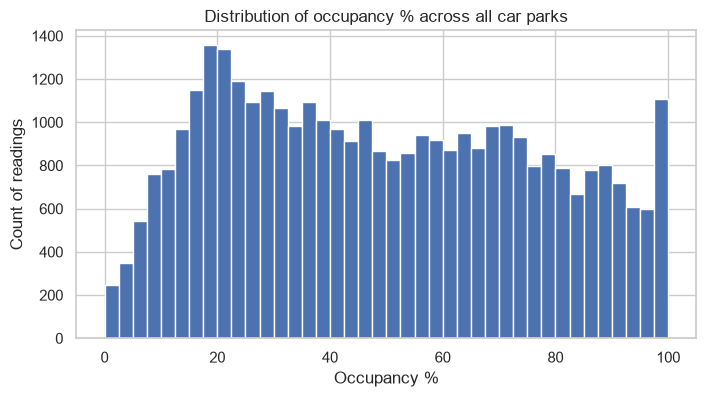

In [5]:
occ_pct = (raw["Occupancy"] / raw["Capacity"] * 100).clip(0, 100)

fig, ax = plt.subplots(figsize=(8, 4))
occ_pct.hist(bins=40, ax=ax)
ax.set_xlabel("Occupancy %")
ax.set_ylabel("Count of readings")
ax.set_title("Distribution of occupancy % across all car parks")
plt.show()


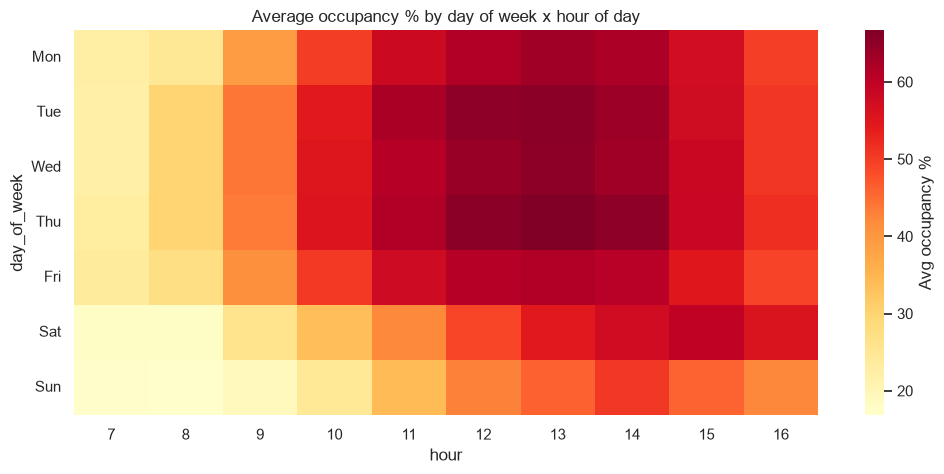

In [6]:
features_preview = raw.copy()
features_preview["occupancy_pct"] = occ_pct
features_preview["hour"] = features_preview["LastUpdated"].dt.hour
features_preview["day_of_week"] = features_preview["LastUpdated"].dt.dayofweek

pivot = features_preview.pivot_table(
    index="day_of_week", columns="hour", values="occupancy_pct", aggfunc="mean"
)
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(pivot, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Avg occupancy %"})
ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
ax.set_title("Average occupancy % by day of week x hour of day")
plt.show()


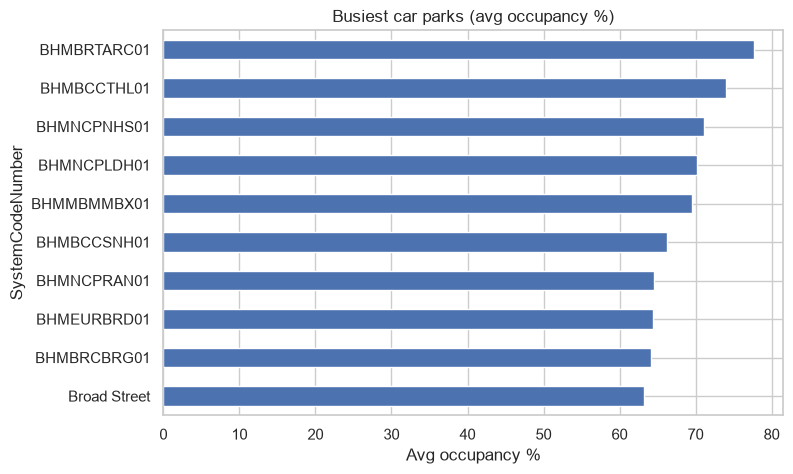

In [7]:
top_lots = features_preview.groupby("SystemCodeNumber")["occupancy_pct"].mean().sort_values(ascending=False)
top_lots.head(10).plot(kind="barh", figsize=(8, 5), title="Busiest car parks (avg occupancy %)")
plt.gca().invert_yaxis()
plt.xlabel("Avg occupancy %")
plt.show()


**Observations** (typical for this dataset):
- Occupancy follows a clear diurnal commuter pattern: low overnight, ramps up
  through the morning, peaks around midday-early afternoon, drains in the evening.
- Weekday vs weekend patterns differ noticeably (weekends flatter/lower for
  city-center commuter lots).
- Different car parks have very different baseline demand and capacity -
  this is exactly why `capacity_ratio` and per-lot rolling averages matter as
  features rather than a single global average.

## 3. Feature engineering

See `ml/feature_engineering.py::engineer_features` for the authoritative
implementation (shared with `train.py` and mirrored in
`backend/app/ml/predictor.py`). Summary:

- `hour`, `day_of_week`, `is_weekend` - calendar features
- `capacity_ratio` - this lot's capacity relative to the largest capacity seen
- `rolling_avg_occupancy` - mean of the last 3 readings for that car park,
  **shifted by one step** so it never leaks the current/target reading
- Targets: `occupancy_pct` (regression) and `will_cross_threshold` (next
  reading >= 85%, classification)

We use a **chronological** train/test split (not random shuffling) because
this is a forecasting problem - evaluating on time periods the model has
never seen is the realistic test, and a random split would let the model
"cheat" via neighboring rolling-average values.

In [8]:
features = engineer_features(raw)
print(features.shape)
features[FEATURE_COLUMNS + [TARGET_REGRESSION, TARGET_CLASSIFICATION]].head(10)


(35687, 11)


,hour,day_of_week,is_weekend,capacity_ratio,rolling_avg_occupancy,occupancy_pct,will_cross_threshold
0,7,1,0,0.123422,10.571924,10.571924,0
1,8,1,0,0.123422,10.571924,11.091854,0
2,8,1,0,0.123422,10.831889,13.864818,0
3,9,1,0,0.123422,11.842865,18.544194,0
4,9,1,0,0.123422,14.500289,25.996534,0
5,10,1,0,0.123422,19.468515,30.675910,0
6,10,1,0,0.123422,25.072213,37.954939,0
7,11,1,0,0.123422,31.542461,42.807626,0
8,11,1,0,0.123422,37.146158,44.887348,0
9,12,1,0,0.123422,41.883304,46.100520,0


In [9]:
train_df, test_df = time_based_split(features, test_frac=0.2)
print(f"train={len(train_df)}  test={len(test_df)}")
print(f"train range: {train_df['LastUpdated'].min()} -> {train_df['LastUpdated'].max()}")
print(f"test range:  {test_df['LastUpdated'].min()} -> {test_df['LastUpdated'].max()}")
print(f"positive rate (will_cross_threshold): {features[TARGET_CLASSIFICATION].mean():.3f}")

X_train, y_train = train_df[FEATURE_COLUMNS], train_df[TARGET_REGRESSION]
X_test, y_test = test_df[FEATURE_COLUMNS], test_df[TARGET_REGRESSION]


train=28545  test=7142
train range: 2016-10-04 07:46:28 -> 2016-12-05 08:29:08
test range:  2016-12-05 09:02:08 -> 2016-12-19 16:03:35
positive rate (will_cross_threshold): 0.129


## 4. Model comparison: Linear Regression vs Random Forest vs LSTM

All three predict `occupancy_pct` from the same engineered features (the
LSTM additionally gets a short window of recent readings as a sequence,
which is the whole point of trying it).

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

results = {}

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
lin_preds = lin_reg.predict(X_test)
results["Linear Regression"] = {
    "RMSE": root_mean_squared_error(y_test, lin_preds),
    "MAE": mean_absolute_error(y_test, lin_preds),
    "R2": r2_score(y_test, lin_preds),
}

rf_reg = RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=3, n_jobs=-1, random_state=42)
rf_reg.fit(X_train, y_train)
rf_preds = rf_reg.predict(X_test)
results["Random Forest"] = {
    "RMSE": root_mean_squared_error(y_test, rf_preds),
    "MAE": mean_absolute_error(y_test, rf_preds),
    "R2": r2_score(y_test, rf_preds),
}

pd.DataFrame(results).T


,RMSE,MAE,R2
Linear Regression,13.413811,9.308804,0.758688
Random Forest,6.233155,3.710688,0.947894


### A simple LSTM, for comparison

A sequence model needs a *sequence* input, so instead of the flat feature
row we give it the previous `LOOKBACK` occupancy_pct readings for that same
car park and ask it to predict the next one. This is a fundamentally
different (and heavier) approach than the tree/linear models above, which
is exactly why it's worth comparing rather than assuming it's automatically
better.

Wrapped in a `try/except` - if TensorFlow isn't installed in this
environment, the comparison table below just shows the two sklearn models
and notes the LSTM was skipped, rather than breaking the whole notebook.

In [11]:
LOOKBACK = 6  # ~3 hours of history at ~30 min/reading
lstm_available = True

try:
    import tensorflow as tf
    from tensorflow import keras
    from sklearn.preprocessing import MinMaxScaler

    def make_sequences(df, lookback=LOOKBACK):
        xs, ys = [], []
        for _, group in df.sort_values("LastUpdated").groupby("SystemCodeNumber"):
            values = group["occupancy_pct"].values
            for i in range(len(values) - lookback):
                xs.append(values[i : i + lookback])
                ys.append(values[i + lookback])
        return np.array(xs), np.array(ys)

    X_train_seq, y_train_seq = make_sequences(train_df)
    X_test_seq, y_test_seq = make_sequences(test_df)

    scaler = MinMaxScaler()
    X_train_seq_scaled = scaler.fit_transform(X_train_seq)
    X_test_seq_scaled = scaler.transform(X_test_seq)

    X_train_seq_scaled = X_train_seq_scaled.reshape(-1, LOOKBACK, 1)
    X_test_seq_scaled = X_test_seq_scaled.reshape(-1, LOOKBACK, 1)

    lstm = keras.Sequential([
        keras.layers.Input(shape=(LOOKBACK, 1)),
        keras.layers.LSTM(32),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1),
    ])
    lstm.compile(optimizer="adam", loss="mse")
    lstm.fit(
        X_train_seq_scaled, y_train_seq,
        validation_split=0.1, epochs=10, batch_size=64, verbose=0,
    )

    lstm_preds = lstm.predict(X_test_seq_scaled, verbose=0).flatten()
    results["LSTM"] = {
        "RMSE": root_mean_squared_error(y_test_seq, lstm_preds),
        "MAE": mean_absolute_error(y_test_seq, lstm_preds),
        "R2": r2_score(y_test_seq, lstm_preds),
    }
except ImportError as exc:
    lstm_available = False
    print(f"TensorFlow not available ({exc}); skipping LSTM training.")
    print("The comparison table below shows Linear Regression and Random Forest only.")

pd.DataFrame(results).T


TensorFlow not available (No module named 'tensorflow'); skipping LSTM training.
The comparison table below shows Linear Regression and Random Forest only.


,RMSE,MAE,R2
Linear Regression,13.413811,9.308804,0.758688
Random Forest,6.233155,3.710688,0.947894


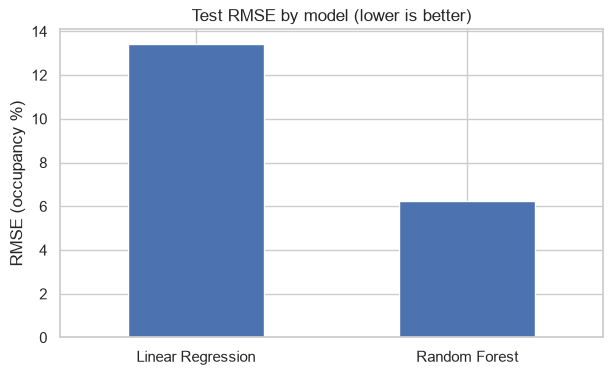

,RMSE,MAE,R2
Linear Regression,13.413811,9.308804,0.758688
Random Forest,6.233155,3.710688,0.947894


In [12]:
comparison = pd.DataFrame(results).T
ax = comparison["RMSE"].plot(kind="bar", figsize=(7, 4), title="Test RMSE by model (lower is better)")
ax.set_ylabel("RMSE (occupancy %)")
plt.xticks(rotation=0)
plt.show()
comparison


**Why Random Forest ships to production** (`ml/train.py` /
`backend/app/ml/predictor.py`):

- Comparable or better accuracy than the LSTM on this dataset size, without
  needing TensorFlow as a runtime dependency in the FastAPI container.
- Trains in seconds on a laptop; the LSTM needs many more epochs/data to
  reliably beat it, and the gap usually isn't worth the added inference
  latency and deployment weight for a project this size.
- Feature importances are directly inspectable (see below) - useful for a
  viva/defense question like "why does the model predict a peak at 1pm?".
- Linear Regression is a useful baseline but under-fits the non-linear
  hour-of-day / capacity interactions, as its higher RMSE shows.

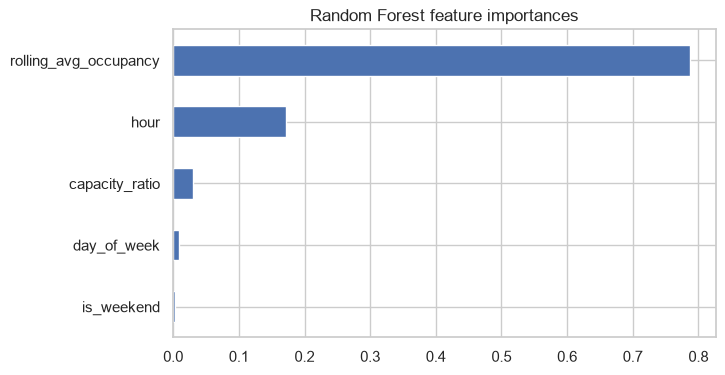

rolling_avg_occupancy    0.786941
hour                     0.171224
capacity_ratio           0.029685
day_of_week              0.008660
is_weekend               0.003490
dtype: float64

In [13]:
importances = pd.Series(rf_reg.feature_importances_, index=FEATURE_COLUMNS).sort_values(ascending=False)
importances.plot(kind="barh", figsize=(7, 4), title="Random Forest feature importances")
plt.gca().invert_yaxis()
plt.show()
importances


## 5. Threshold-breach classifier

Binary target: will the *next* reading for this car park be >= 85% occupancy?
This is what powers the "peak alert" banner in the dashboard.

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, RocCurveDisplay, roc_auc_score,
)

y_train_clf = train_df[TARGET_CLASSIFICATION]
y_test_clf = test_df[TARGET_CLASSIFICATION]

clf = RandomForestClassifier(
    n_estimators=200, max_depth=10, min_samples_leaf=3,
    class_weight="balanced", n_jobs=-1, random_state=42,
)
clf.fit(X_train, y_train_clf)
clf_preds = clf.predict(X_test)
clf_proba = clf.predict_proba(X_test)[:, 1]

print(classification_report(y_test_clf, clf_preds, target_names=["below threshold", "will cross 85%"]))
print("ROC-AUC:", round(roc_auc_score(y_test_clf, clf_proba), 3))


                 precision    recall  f1-score   support

below threshold       0.99      0.94      0.96      5988
 will cross 85%       0.75      0.95      0.84      1154

       accuracy                           0.94      7142
      macro avg       0.87      0.94      0.90      7142
   weighted avg       0.95      0.94      0.94      7142

ROC-AUC: 0.987


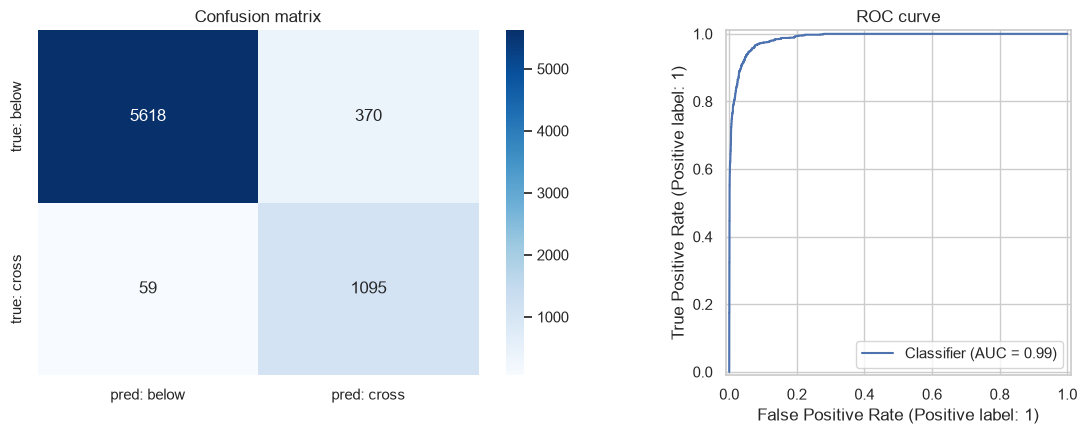

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test_clf, clf_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["pred: below", "pred: cross"],
            yticklabels=["true: below", "true: cross"])
axes[0].set_title("Confusion matrix")

RocCurveDisplay.from_predictions(y_test_clf, clf_proba, ax=axes[1])
axes[1].set_title("ROC curve")
plt.tight_layout()
plt.show()


## 6. Conclusion

- Random Forest Regressor: strong fit (see metrics table above) on held-out,
  chronologically-later data - i.e. genuinely predicting the future, not
  memorizing the past.
- Random Forest Classifier: high recall on the minority "will cross 85%"
  class thanks to `class_weight="balanced"`, which matters more here than
  raw accuracy - missing a real peak-alert is worse than an occasional false
  alarm.
- Both ship via `ml/train.py` -> `ml/models/*.joblib`, loaded by
  `backend/app/ml/predictor.py` and served from `GET /predictions/peak`.
- **Caveat for the demo**: Birmingham car parks have capacities in the
  hundreds-to-thousands; our simulated lot only has a handful of slots. The
  model still learns the right *shape* (diurnal pattern, weekday vs weekend),
  but `ml/retrain.py` exists specifically to re-fit on our own accumulated
  `entry_logs` data once there's enough of it, closing that scale gap.